In [1]:
print("WorkSafe Evidence Intelligence - project started")

WorkSafe Evidence Intelligence - project started


In [3]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

print('Path Is: ', Path.cwd())

Path Is:  c:\Users\Sahand\Desktop\python\GitHub\worksafe-evidence-intelligence\Notebooks


In [4]:
project_root = Path.cwd().parent

working_data_path = (project_root / 'data' / 'interim' / 'osha_sir_working.parquet')

print(f'Project Root: {project_root}')
print(f'Working Data Path: {working_data_path}')

Project Root: c:\Users\Sahand\Desktop\python\GitHub\worksafe-evidence-intelligence
Working Data Path: c:\Users\Sahand\Desktop\python\GitHub\worksafe-evidence-intelligence\data\interim\osha_sir_working.parquet


In [6]:
eda_df = pd.read_parquet(working_data_path, engine='pyarrow')
print(f'Shape: {eda_df.shape}')
print(f'Dtypes: {eda_df.dtypes}')
print(f'Top 5 Rows: {eda_df.head(5)}')

Shape: (105996, 29)
Dtypes: ID                                 int64
UPA                                int64
EventDate                 datetime64[ns]
Employer                          object
Address1                          object
Address2                          object
City                              object
State                             object
Zip                       string[python]
Latitude                         float64
Longitude                        float64
Primary NAICS             string[python]
Hospitalized                     float64
Amputation                       float64
Loss of Eye                      float64
Inspection                string[python]
Final Narrative                   object
Nature                             int64
NatureTitle                       object
Part of Body                       int64
Part of Body Title                object
Event                              int64
EventTitle                        object
Source                       

In [7]:
event_counts = eda_df['EventTitle'].value_counts(dropna=False).head(15)
event_counts

EventTitle
Caught in running equipment or machinery during regular operation             6694
Other fall to lower level, unspecified                                        5921
Caught in running equipment or machinery during maintenance, cleaning         5298
Compressed or pinched by shifting objects or equipment                        4985
Other fall to lower level less than 6 feet                                    4009
Fall on same level due to slipping                                            3681
Fall on same level due to tripping over an object                             2660
Struck against moving part of machinery or equipment                          2235
Exposure to environmental heat                                                2196
Caught in or compressed by equipment or objects, unspecified                  2153
Injured by slipping or swinging object held by injured worker                 2126
Struck by falling object or equipment, n.e.c.                               

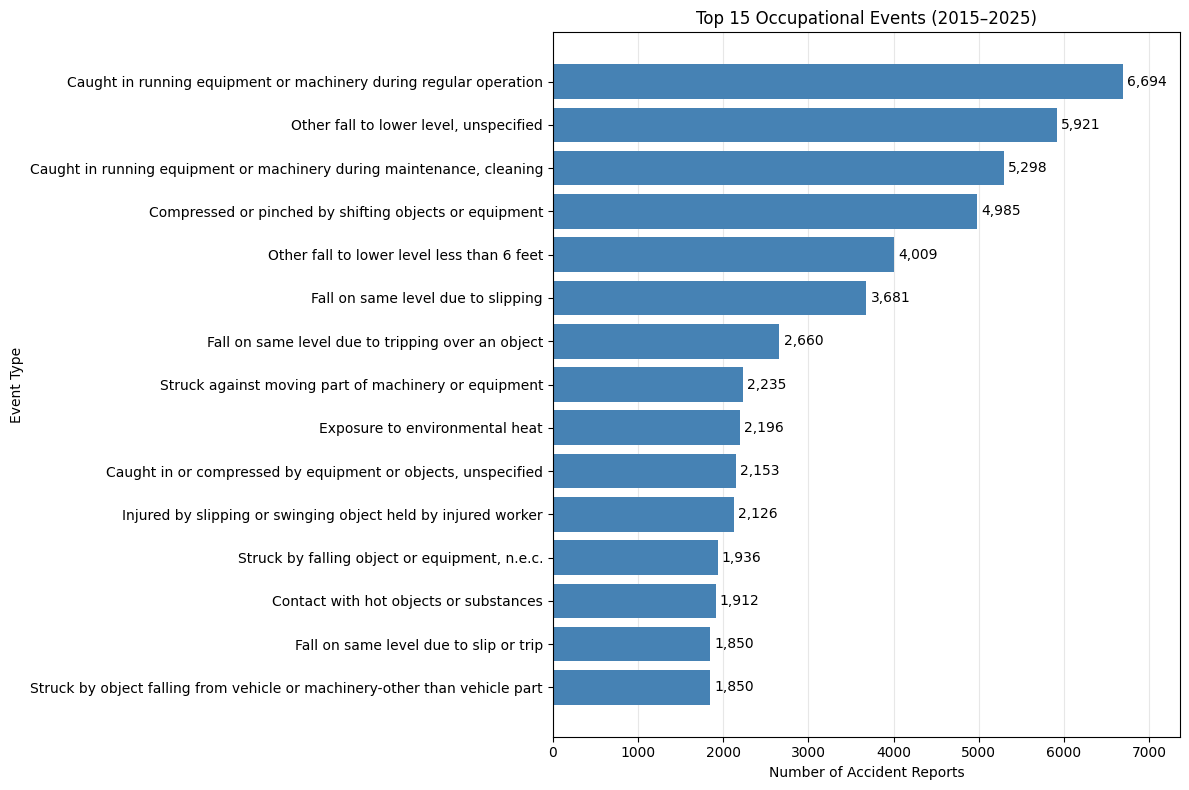

In [ ]:
# Create Figure and Axes
fig, ax = plt.subplots(figsize=(12, 8))

# Create Horizontal Bar Chart
bars = ax.barh(y=event_counts.index,width=event_counts.values, color='steelblue')
ax.invert_yaxis()
ax.bar_label(bars, labels=[f'{value:,}' for value in event_counts.values], padding=3)
ax.set_xlim(left=0, right=event_counts.max() * 1.1)
ax.set_title('Top 15 Occupational Events (2015–2025)')
ax.set_xlabel('Number of Accident Reports')
ax.set_ylabel('Event Type')
ax.set_axisbelow(True)
ax.grid(axis='x',alpha=0.3)
fig.tight_layout()
figures_dir = project_root / 'reports' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
figure_path = figures_dir / 'top_15_occupational_events.png'
fig.savefig(figure_path, dpi=300, bbox_inches='tight')
# Display Chart
plt.show()

In [20]:
figure_path.exists()
figure_path.stat().st_size

342917

## Figure 1. Most Frequently Reported Occupational Events (2015–2025)

### 1. Overview

This figure presents the 15 most frequently reported occupational event categories in the OSHA Severe Injury Reports (SIR) dataset covering the period from January 2015 to November 2025.

The analysis is based on 105,996 incident records. Event frequencies were calculated using the `EventTitle` variable, with each record representing one reported incident.

A horizontal bar chart was selected to improve the readability of event descriptions and facilitate comparisons between categories.

### 2. Key Findings

The three most frequently reported event categories are:

1. **Caught in running equipment or machinery during regular operation:** 6,694 records.
2. **Other fall to lower level, unspecified:** 5,921 records.
3. **Caught in running equipment or machinery during maintenance and cleaning:** 5,298 records.

Several notable patterns emerge from the results:

- Machinery-related incidents appear prominently in the distribution, with two machinery-related categories ranking among the top three event types.
- Both routine equipment operation and maintenance or cleaning activities are represented among the most frequent incident categories.
- Falls to lower levels also constitute a substantial proportion of reported incidents, highlighting another important area for further investigation.
- The results indicate that machinery-related incidents and fall-related events deserve particular attention in subsequent analyses.

### 3. HSE Interpretation and Implications

The frequency of incidents involving running machinery suggests the importance of examining machine safeguarding and the effectiveness of operational safety procedures.

The presence of machinery-related incidents during maintenance and cleaning activities also highlights the need to investigate hazardous energy control practices, including Lockout/Tagout (LOTO) procedures where applicable.

Potential areas for further investigation include:

- Adequacy of machine guards, safety interlocks, and protective devices.
- Effectiveness of hazardous energy isolation procedures during maintenance and cleaning.
- Compliance with safe operating and maintenance procedures.
- Worker training, supervision, and awareness of machinery-related hazards.
- Identification of recurring unsafe conditions and opportunities for preventive interventions.

These findings provide initial directions for further investigation rather than definitive evidence of incident causes.

### 4. Analytical Limitations

Several limitations should be considered when interpreting this figure:

- The chart represents absolute incident counts rather than incident rates.
- Workforce size, hours worked, and exposure levels are not incorporated into this comparison.
- Higher reporting frequency does not necessarily indicate a higher individual risk or greater incident severity.
- Event classifications describe reported incident mechanisms and do not independently establish underlying root causes.
- Only the 15 most frequently reported event categories are displayed.

Further analysis incorporating exposure data, incident severity, contributing factors, and relevant workplace characteristics would be necessary for a more comprehensive risk assessment.

### 5. Conclusion

The exploratory analysis identifies machinery-related incidents and falls as important categories for further investigation within the OSHA SIR dataset.

In particular, incidents occurring during routine machinery operation and maintenance or cleaning activities represent relevant starting points for more detailed HSE investigations.

These findings will help guide subsequent exploratory analyses and support the development of evidence-based occupational injury prevention strategies within the WorkSafe Evidence Intelligence (WEI) project.